# Estimate a turbulent tube coefficient using synthetic wall temperature readings.

Run in a Python environment with OneSimulation 0.2.0, NumPy, SciPy and Matplotlib. Change the input data and rerun to compare with the saved reference output.

fitted prefactor = 0.02494
RMS temperature residual = 0.0299 K
predicted rise at Re=30000 = 1.655 K


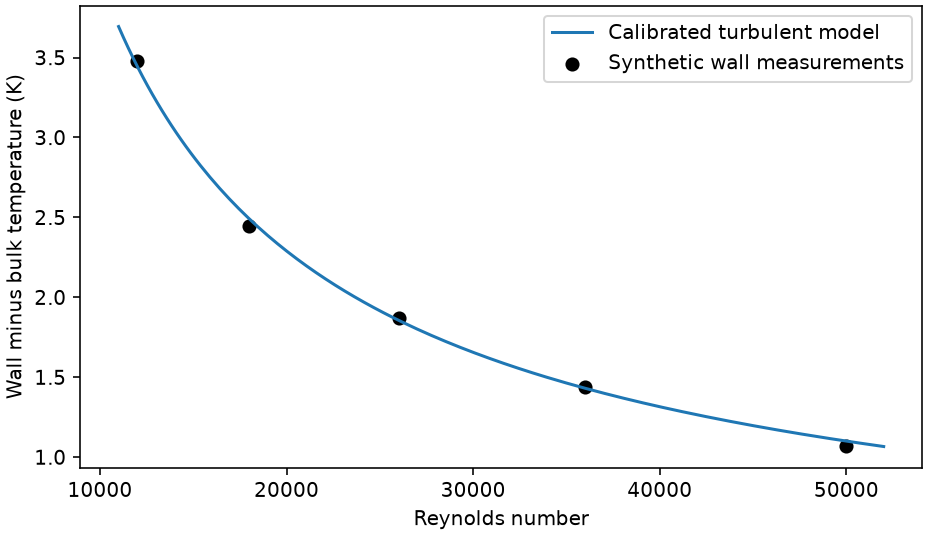

In [1]:
"""Estimate a turbulent tube coefficient using synthetic wall temperature readings."""
import numpy as np
import matplotlib.pyplot as plt
from onesim.numerics.nonlinear import LeastSquares

reynolds = np.array([12000., 18000., 26000., 36000., 50000.])
q, diameter, conductivity, prandtl = 9000.0, 0.02, 0.60, 5.0
def superheat(coefficient, re):
    nusselt = coefficient*re**0.8*prandtl**0.4
    return q*diameter/(conductivity*nusselt)

readings = superheat(0.025, reynolds)+np.array([0.04,-0.04,0.02,0.01,-0.03])
fit = LeastSquares().solve(lambda c: superheat(c[0], reynolds)-readings,
                           [0.023], bounds=([0.005],[0.08]))
assert fit.success
coefficient = fit.x[0]
print(f"fitted prefactor = {coefficient:.5f}")
print(f"RMS temperature residual = {np.sqrt(np.mean(fit.fun**2)):.4f} K")
print(f"predicted rise at Re=30000 = {superheat(coefficient, 30000):.3f} K")
fig, ax = plt.subplots(figsize=(6.4,3.7), layout="constrained")
re = np.linspace(11000,52000,160)
ax.plot(re, superheat(coefficient,re), label="Calibrated turbulent model")
ax.scatter(reynolds,readings,color="black",label="Synthetic wall measurements")
ax.set(xlabel="Reynolds number",ylabel="Wall minus bulk temperature (K)")
ax.legend()
plt.show()
